# Pipeline Multimodal Bebas Kebocoran: Frozen BERT (Judul) + Frozen Longformer (Full-Text) + FinBERT + BERTopic + Sentimen×Arah Ekstrem + MLP/LSTM/Bi-LSTM & Studi Ablasi

Notebook ini mengimplementasikan pipeline **end-to-end bebas *data leakage*** (**split kronologis dari awal** `70% Train / 15% Val / 15% Test`):

1. **Split dari Awal**: Seluruh *fitting* (PCA, BERTopic, UMAP, `StandardScaler`, kuantil sentimen tinggi/ekstrem, Classifier Stage 1 + 5-Fold OOF, MLP, LSTM, Bi-LSTM, dan *hyperparameter tuning*) dilakukan **hanya pada Train/Val** tanpa pernah melihat Test Set.
2. **Representasi Teks Ganda (Freeze Layer) + Studi Ablasi Embedding**:
   - **BERT (`bert-base-uncased`, frozen)** untuk **judul berita** (`all_title`) $\to$ direduksi dengan PCA.
   - **Longformer (`allenai/longformer-base-4096`, frozen, `max_length=1024`)** untuk **`full_text`** (`all_full_text`) $\to$ direduksi dengan PCA.
   - **Studi Ablasi Embedding**: membandingkan `BERT Title Only`, `Longformer Full-Text Only`, dan `BERT Title + Longformer Full-Text`.
3. **Sentiment Analysis & Polaritas dengan FinBERT + Studi Ablasi Sentimen**:
   - Menggunakan `ProsusAI/finbert` (frozen) dengan **logika kurs Indonesia**:
     $$\text{sent\_polarity} = P_{\text{pos}} - P_{\text{neg}}, \qquad \text{kurs\_pressure} = -\text{sent\_polarity} = P_{\text{neg}} - P_{\text{pos}} \in [-1, +1]$$
   - Berita internasional **Negatif** $\Rightarrow$ Rupiah **Naik** (`kurs_pressure > 0`); **Positif** $\Rightarrow$ Rupiah **Turun** (`kurs_pressure < 0`); **Netral** tetap memakai **kecenderungannya** (misal `-0.10` artinya cenderung menurun tapi sedikit).
   - **Studi Ablasi Sentimen**: membandingkan *Tanpa Sentimen* vs *Sentimen Diskrit/Biner* vs *FinBERT Kontinu + Kecenderungan Netral*.
4. **Topic Modelling BERTopic + Reduksi Dimensi (PCA & UMAP)**:
   - BERTopic di-*fit* **hanya pada Train berberita**, lalu direduksi dengan **PCA** dan **UMAP 2D** (fit hanya di Train).
5. **Stage 1 Classifier + Fitur `Sentimen × Arah` (Tinggi & Ekstrem)**:
   - Melatih Classifier Arah Return (dengan 5-Fold OOF di Train), membentuk `sent_x_dir`, serta menandai **Sentimen Tinggi** (kuantil ke-70 Train) dan **Sentimen Ekstrem** (kuantil ke-90 Train) — terutama ketika sentimen ekstrem mendorong **penurunan/kenaikan ekstrem** (`extreme_amp_x_dir`, `flag_turun_ekstrem`, `flag_naik_ekstrem`).
6. **Time Series + MLP, LSTM, Bi-LSTM + Fine-Grained Tuning Model Terbaik + Studi Ablasi Fitur Lengkap**:
   - Membandingkan **MLP**, **LSTM**, dan **Bi-LSTM**, melakukan *hyperparameter tuning* lanjutan pada model terbaik, serta menjalankan **Studi Ablasi Aditif & Leave-One-Group-Out (LOGO)** untuk mengidentifikasi **fitur mana yang paling berpengaruh**.


## 1. Setup Lingkungan & Seed Deterministik


In [1]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["USE_TF"] = "0"

import gc
import re
import copy
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sentence_transformers import SentenceTransformer

from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed: int = SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
})
sns.set_style("whitegrid")

print(f"Device aktif : {DEVICE}")
print(f"PyTorch      : {torch.__version__}")


C:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device aktif : cpu
PyTorch      : 2.13.0+cpu


## 2. Pemuatan Dataset & Split Kronologis di Awal (Zero Leakage)

Membaca `merged_data_clean.csv`, menghitung `rate_mid`, `log_ret`, dan target arah `y_dir` (`1 = Kurs Naik`, `0 = Kurs Turun`), lalu **langsung melakukan split kronologis `70% Train / 15% Val / 15% Test` di awal** sebelum ekstraksi fitur parametrik apa pun.


In [2]:
DATA_CANDIDATES = [
    Path("data/processed/merged_data_clean.csv"),
    Path("../data/processed/merged_data_clean.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Tidak menemukan data/processed/merged_data_clean.csv!")

PROJECT_ROOT = DATA_PATH.parent.parent.parent
LONGFORMER_CACHE_PATH = PROJECT_ROOT / "data" / "cache_embeddings" / "longformer_daily_fulltext_1024.npz"

df = pd.read_csv(DATA_PATH)
date_col = "Tanggal_dt" if "Tanggal_dt" in df.columns else "tanggal"
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

if "rate_mid" not in df.columns:
    df["rate_mid"] = (df["Kurs Jual"] + df["Kurs Beli"]) / 2.0

df["log_ret"] = np.log(df["rate_mid"] / df["rate_mid"].shift(1))
df = df.dropna(subset=["log_ret"]).reset_index(drop=True)
df["y_dir"] = (df["log_ret"] > 0).astype(int)

def clean_text_keep_case(text) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["title_clean"] = df["all_title"].fillna("").apply(clean_text_keep_case)
df["fulltext_clean"] = df["all_full_text"].fillna("").apply(clean_text_keep_case)
df["norm_clean"] = df["all_normalized_text"].fillna("").apply(clean_text_keep_case)
df["has_news"] = (df["news_count"].fillna(0) > 0).astype(int)

# SPLIT KRONOLOGIS DI AWAL (70% Train / 15% Val / 15% Test)
n_total = len(df)
train_end_idx = int(n_total * 0.70)
val_end_idx = int(n_total * 0.85)

df["split"] = "test"
df.loc[:train_end_idx - 1, "split"] = "train"
df.loc[train_end_idx:val_end_idx - 1, "split"] = "val"

train_end_date = df.loc[train_end_idx - 1, date_col]
val_end_date = df.loc[val_end_idx - 1, date_col]

is_tr = (df["split"] == "train").values
is_va = (df["split"] == "val").values
is_te = (df["split"] == "test").values

print(f"Dataset: {n_total:,} hari perdagangan valid")
for sp, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    print(
        f"  {sp:5s}: {len(sub):4d} hari | {sub[date_col].min().date()} s/d {sub[date_col].max().date()} "
        f"| Naik={sub['y_dir'].mean()*100:.1f}% | Ada Berita={sub['has_news'].mean()*100:.1f}%"
    )


Dataset: 1,201 hari perdagangan valid
  Train:  840 hari | 2021-09-02 s/d 2025-02-18 | Naik=55.4% | Ada Berita=86.8%
  Val  :  180 hari | 2025-02-19 s/d 2025-11-21 | Naik=53.3% | Ada Berita=88.9%
  Test :  181 hari | 2025-11-24 s/d 2026-09-01 | Naik=57.5% | Ada Berita=98.3%


## 3. Embedding Frozen BERT (Judul) & Frozen Longformer (Full-Text) + Reduksi PCA & Studi Ablasi Embedding

- **BERT Title (`bert-base-uncased`, frozen)**: setiap judul dalam `all_title` dipecah (`" | "`), di-encode (`max_length=48`), dan dirata-ratakan per hari (`768-d`) $\to$ **PCA-8 (fit murni di Train)**.
- **Longformer Full-Text (`allenai/longformer-base-4096`, frozen)**: dokumen `all_full_text` harian di-encode (`max_length=1024`, attention-masked mean pooling, `768-d`) $\to$ **PCA-8 (fit murni di Train)**.
- **Studi Ablasi Embedding**: membandingkan performa klasifikasi arah kurs untuk **BERT Title Only** vs **Longformer Full-Text Only** vs **BERT Title + Longformer Full-Text**.


In [3]:
def load_hf_tokenizer_and_model(model_cls, model_name: str):
    try:
        tok = AutoTokenizer.from_pretrained(model_name, local_files_only=True)
        mod = model_cls.from_pretrained(model_name, local_files_only=True)
    except Exception:
        tok = AutoTokenizer.from_pretrained(model_name)
        mod = model_cls.from_pretrained(model_name)
    return tok, mod

# --- 3A. Frozen BERT untuk Judul ---
daily_title_lists = []
unique_titles_set = set()
for raw_t in df["all_title"].fillna(""):
    parts = [clean_text_keep_case(p) for p in str(raw_t).split(" | ")]
    parts = [p for p in parts if p and p.lower() != "nan"]
    daily_title_lists.append(parts)
    unique_titles_set.update(parts)
unique_titles = sorted(unique_titles_set)
print(f"Total judul unik: {len(unique_titles):,}")

bert_tok, bert_mod = load_hf_tokenizer_and_model(AutoModel, "bert-base-uncased")
bert_mod = bert_mod.to(DEVICE)
for p in bert_mod.parameters():
    p.requires_grad = False
bert_mod.eval()

title_emb_map = {}
bs = 64
with torch.no_grad():
    for i in range(0, len(unique_titles), bs):
        batch_txt = unique_titles[i:i + bs]
        enc = bert_tok(batch_txt, padding=True, truncation=True, max_length=48, return_tensors="pt").to(DEVICE)
        out = bert_mod(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1).float()
        pooled = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        for t_str, vec in zip(batch_txt, pooled.cpu().numpy()):
            title_emb_map[t_str] = vec

del bert_mod, bert_tok
gc.collect()

daily_bert_title = np.zeros((len(df), 768), dtype=np.float32)
for i, t_list in enumerate(daily_title_lists):
    if t_list:
        daily_bert_title[i] = np.mean([title_emb_map[t] for t in t_list], axis=0)

# --- 3B. Frozen Longformer untuk Full-Text ---
date_strs = df[date_col].dt.strftime("%Y-%m-%d").values
loaded_longformer = False
if LONGFORMER_CACHE_PATH.exists():
    npz = np.load(LONGFORMER_CACHE_PATH, allow_pickle=True)
    if np.array_equal(npz["dates"].astype(str), date_strs.astype(str)):
        daily_longformer_ft = npz["emb"].astype(np.float32)
        loaded_longformer = True
        print(f"Frozen Longformer Full-Text dimuat dari cache terverifikasi: {LONGFORMER_CACHE_PATH} {daily_longformer_ft.shape}")

if not loaded_longformer:
    print("Menjalankan Frozen Longformer (allenai/longformer-base-4096, max_length=1024) pada full_text harian...")
    lf_tok, lf_mod = load_hf_tokenizer_and_model(AutoModel, "allenai/longformer-base-4096")
    lf_mod = lf_mod.to(DEVICE)
    for p in lf_mod.parameters():
        p.requires_grad = False
    lf_mod.eval()

    daily_longformer_ft = np.zeros((len(df), 768), dtype=np.float32)
    news_idx = np.where(df["has_news"].values == 1)[0]
    lf_texts = [df.loc[i, "fulltext_clean"] or df.loc[i, "title_clean"] for i in news_idx]
    order = sorted(range(len(lf_texts)), key=lambda k: len(lf_texts[k]))
    lf_embs = [None] * len(lf_texts)
    with torch.no_grad():
        for s in range(0, len(order), 16):
            b_ord = order[s:s + 16]
            b_txt = [lf_texts[k] for k in b_ord]
            enc = lf_tok(b_txt, padding=True, truncation=True, max_length=1024, return_tensors="pt").to(DEVICE)
            out = lf_mod(**enc).last_hidden_state
            mask = enc["attention_mask"].unsqueeze(-1).float()
            pooled = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
            for k, v in zip(b_ord, pooled.cpu().numpy().astype(np.float32)):
                lf_embs[k] = v
    for pos, orig_i in enumerate(news_idx):
        daily_longformer_ft[orig_i] = lf_embs[pos]
    LONGFORMER_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    np.savez(LONGFORMER_CACHE_PATH, dates=date_strs, emb=daily_longformer_ft)
    del lf_mod, lf_tok
    gc.collect()

# --- 3C. Reduksi Dimensi PCA (FIT HANYA DI TRAIN SET!) ---
BERT_PCA_DIM = 8
LONG_PCA_DIM = 8

sc_bert = StandardScaler().fit(daily_bert_title[is_tr])
pca_bert = PCA(n_components=BERT_PCA_DIM, random_state=SEED).fit(sc_bert.transform(daily_bert_title[is_tr]))
X_bert_pca = pca_bert.transform(sc_bert.transform(daily_bert_title))
bert_pca_cols = [f"bert_pca_{i}" for i in range(BERT_PCA_DIM)]
for i, c in enumerate(bert_pca_cols):
    df[c] = X_bert_pca[:, i]

sc_long = StandardScaler().fit(daily_longformer_ft[is_tr])
pca_long = PCA(n_components=LONG_PCA_DIM, random_state=SEED).fit(sc_long.transform(daily_longformer_ft[is_tr]))
X_long_pca = pca_long.transform(sc_long.transform(daily_longformer_ft))
long_pca_cols = [f"long_pca_{i}" for i in range(LONG_PCA_DIM)]
for i, c in enumerate(long_pca_cols):
    df[c] = X_long_pca[:, i]

print(f"PCA BERT Title ({BERT_PCA_DIM} komp.)     | Explained Var (Train): {pca_bert.explained_variance_ratio_.sum()*100:.2f}%")
print(f"PCA Longformer FT ({LONG_PCA_DIM} komp.)  | Explained Var (Train): {pca_long.explained_variance_ratio_.sum()*100:.2f}%")

# --- 3D. Studi Ablasi Embedding (BERT Title vs Longformer Full-Text vs Gabungan) ---
y_tr_dir, y_va_dir, y_te_dir = df.loc[is_tr, "y_dir"].values, df.loc[is_va, "y_dir"].values, df.loc[is_te, "y_dir"].values
emb_ablation_rows = []
for emb_name, cols in [
    ("1. BERT Title Only (PCA-8)", bert_pca_cols),
    ("2. Longformer Full-Text Only (PCA-8)", long_pca_cols),
    ("3. BERT Title + Longformer FT (PCA-16)", bert_pca_cols + long_pca_cols),
]:
    sc_e = StandardScaler().fit(df.loc[is_tr, cols])
    clf_e = LogisticRegression(C=0.05, class_weight="balanced", max_iter=1000, random_state=SEED).fit(
        sc_e.transform(df.loc[is_tr, cols]), y_tr_dir
    )
    p_va = clf_e.predict_proba(sc_e.transform(df.loc[is_va, cols]))[:, 1]
    p_te = clf_e.predict_proba(sc_e.transform(df.loc[is_te, cols]))[:, 1]
    emb_ablation_rows.append({
        "Ablasi Embedding": emb_name,
        "Val BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_va_dir, p_va), 4),
        "Test BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_te >= 0.5).astype(int)) * 100, 2),
        "Test ROC-AUC": round(roc_auc_score(y_te_dir, p_te), 4),
    })

emb_ablation_df = pd.DataFrame(emb_ablation_rows).set_index("Ablasi Embedding")
print("\n=== STUDI ABLASI EMBEDDING (ARAH RETURN) ===")
display(emb_ablation_df)


Total judul unik: 4,138


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  26%|██▌       | 52/199 [00:00<00:00, 481.49it/s]

Loading weights:  51%|█████     | 101/199 [00:00<00:00, 299.55it/s]

Loading weights:  68%|██████▊   | 135/199 [00:00<00:00, 306.01it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 468.91it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Frozen Longformer Full-Text dimuat dari cache terverifikasi: data\cache_embeddings\longformer_daily_fulltext_1024.npz (1201, 768)


PCA BERT Title (8 komp.)     | Explained Var (Train): 45.19%
PCA Longformer FT (8 komp.)  | Explained Var (Train): 54.52%



=== STUDI ABLASI EMBEDDING (ARAH RETURN) ===


,Val BalAcc (%),Val ROC-AUC,Test BalAcc (%),Test ROC-AUC
Ablasi Embedding,,,,
1. BERT Title Only (PCA-8),52.98,0.5050,54.20,0.5235
2. Longformer Full-Text Only (PCA-8),52.08,0.5176,49.44,0.5132
3. BERT Title + Longformer FT (PCA-16),52.53,0.5207,53.79,0.5350


## 4. Analisis Sentimen & Polaritas dengan FinBERT (Logika Kurs Indonesia) + Studi Ablasi Sentimen

Menggunakan `ProsusAI/finbert` (bobot dibekukan) untuk menghitung polaritas berita internasional dan mengubahnya ke tekanan kurs Indonesia:
- $\text{sent\_polarity} = P_{\text{pos}} - P_{\text{neg}} \in [-1, +1]$
- $\text{kurs\_pressure} = -\text{sent\_polarity} = P_{\text{neg}} - P_{\text{pos}} \in [-1, +1]$
  - Berita **Negatif** $\to$ `kurs_pressure > 0` $\to$ **Rupiah Naik**.
  - Berita **Positif** $\to$ `kurs_pressure < 0` $\to$ **Rupiah Turun**.
  - Berita **Netral** $\to$ tetap memakai **kecenderungannya** (misal `-0.10` = cenderung turun sedikit).
- **Studi Ablasi Sentimen**: membandingkan *Tanpa Sentimen* vs *Sentimen Diskrit (`+1 / 0 / -1` tanpa kecenderungan netral)* vs *FinBERT Kontinu + Kecenderungan Netral*.


In [4]:
fin_tok, fin_mod = load_hf_tokenizer_and_model(AutoModelForSequenceClassification, "ProsusAI/finbert")
fin_mod = fin_mod.to(DEVICE)
for p in fin_mod.parameters():
    p.requires_grad = False
fin_mod.eval()

id2label = {int(k): str(v).lower() for k, v in fin_mod.config.id2label.items()}
pos_idx = next(i for i, lbl in id2label.items() if "pos" in lbl)
neg_idx = next(i for i, lbl in id2label.items() if "neg" in lbl)
neu_idx = next(i for i, lbl in id2label.items() if "neu" in lbl)

fin_map = {}
with torch.no_grad():
    for i in range(0, len(unique_titles), 64):
        batch_txt = unique_titles[i:i + 64]
        enc = fin_tok(batch_txt, padding=True, truncation=True, max_length=48, return_tensors="pt").to(DEVICE)
        probs = torch.softmax(fin_mod(**enc).logits, dim=-1).cpu().numpy()
        for t_str, p_arr in zip(batch_txt, probs):
            p_pos, p_neg, p_neu = float(p_arr[pos_idx]), float(p_arr[neg_idx]), float(p_arr[neu_idx])
            sent_pol = p_pos - p_neg
            kurs_press = p_neg - p_pos
            cls_idx = int(np.argmax([p_pos, p_neg, p_neu]))
            cls_name = ["Positif", "Negatif", "Netral"][cls_idx]
            # Sentimen diskrit membuang kecenderungan berita netral (=0)
            discrete_press = -1.0 if cls_idx == 0 else (1.0 if cls_idx == 1 else 0.0)
            fin_map[t_str] = {
                "finbert_pos": p_pos,
                "finbert_neg": p_neg,
                "finbert_neu": p_neu,
                "sent_polarity": sent_pol,
                "kurs_pressure": kurs_press,
                "kurs_pressure_discrete": discrete_press,
                "sent_magnitude": abs(kurs_press),
                "sent_ratio": (p_pos - p_neg) / (p_pos + p_neg + 1e-8),
                "sent_class": cls_name,
            }

del fin_mod, fin_tok
gc.collect()

sent_cols = [
    "finbert_pos", "finbert_neg", "finbert_neu",
    "sent_polarity", "kurs_pressure", "kurs_pressure_discrete", "sent_magnitude", "sent_ratio",
]
daily_sent = np.zeros((len(df), len(sent_cols)), dtype=np.float32)
for i, t_list in enumerate(daily_title_lists):
    if t_list:
        mat = np.array([[fin_map[t][c] for c in sent_cols] for t in t_list], dtype=np.float32)
        daily_sent[i] = mat.mean(axis=0)
for j, c in enumerate(sent_cols):
    df[c] = daily_sent[:, j]

# Contoh berita Positif, Negatif, dan Netral beserta kecenderungannya
sample_art = pd.DataFrame([{"title": t, **v} for t, v in fin_map.items()])
ex_df = pd.concat([
    sample_art[sample_art["sent_class"] == "Negatif"].sort_values("sent_magnitude", ascending=False).head(2),
    sample_art[sample_art["sent_class"] == "Positif"].sort_values("sent_magnitude", ascending=False).head(2),
    sample_art[(sample_art["sent_class"] == "Netral") & (sample_art["sent_magnitude"].between(0.05, 0.20))].head(2),
], ignore_index=True)
display(ex_df[["title", "sent_class", "finbert_pos", "finbert_neg", "finbert_neu", "kurs_pressure"]].round(4))

# Studi Ablasi Sentimen FinBERT (bersama BERT+Longformer PCA)
base_emb_cols = bert_pca_cols + long_pca_cols
sent_ablation_rows = []
for s_name, cols in [
    ("1. Tanpa Sentimen FinBERT (Embedding Only)", base_emb_cols),
    ("2. + Sentimen Diskrit (+1/0/-1, Netral=0)", base_emb_cols + ["kurs_pressure_discrete", "has_news"]),
    ("3. + FinBERT Kontinu & Kecenderungan Netral", base_emb_cols + ["kurs_pressure", "sent_magnitude", "sent_ratio", "finbert_pos", "finbert_neg", "finbert_neu", "has_news"]),
]:
    sc_s = StandardScaler().fit(df.loc[is_tr, cols])
    clf_s = LogisticRegression(C=0.05, class_weight="balanced", max_iter=1000, random_state=SEED).fit(
        sc_s.transform(df.loc[is_tr, cols]), y_tr_dir
    )
    p_va = clf_s.predict_proba(sc_s.transform(df.loc[is_va, cols]))[:, 1]
    p_te = clf_s.predict_proba(sc_s.transform(df.loc[is_te, cols]))[:, 1]
    sent_ablation_rows.append({
        "Ablasi Sentimen FinBERT": s_name,
        "Val BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_va_dir, p_va), 4),
        "Test BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_te >= 0.5).astype(int)) * 100, 2),
        "Test ROC-AUC": round(roc_auc_score(y_te_dir, p_te), 4),
    })

sent_ablation_df = pd.DataFrame(sent_ablation_rows).set_index("Ablasi Sentimen FinBERT")
print("\n=== STUDI ABLASI SENTIMEN FINBERT ===")
display(sent_ablation_df)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   7%|▋         | 14/201 [00:00<00:01, 103.56it/s]

Loading weights:  12%|█▏        | 25/201 [00:00<00:01, 95.94it/s] 

Loading weights:  17%|█▋        | 35/201 [00:00<00:02, 61.95it/s]

Loading weights:  21%|██▏       | 43/201 [00:00<00:04, 38.61it/s]

Loading weights:  24%|██▍       | 49/201 [00:01<00:04, 33.68it/s]

... (3 outputs left out)

Loading weights: 100%|██████████| 201/201 [00:01<00:00, 130.23it/s]

,title,sent_class,finbert_pos,finbert_neg,finbert_neu,kurs_pressure
0,"Retail sales fell 0.9% in May, worse than expe...",Negatif,0.0077,0.9767,0.0155,0.9690
1,"Bitcoin extends its slide to start May, fallin...",Negatif,0.0070,0.9727,0.0203,0.9657
2,"Samsung expects memory chip demand to improve,...",Positif,0.9568,0.0193,0.0239,-0.9375
3,Delta CEO sees record earnings in reach again ...,Positif,0.9544,0.0198,0.0257,-0.9346
4,"10 torture sites in 1 town: Russia sowed pain,...",Netral,0.0352,0.1964,0.7685,0.1612
5,"100 days of war, Delta’s trans-Pacific push, Y...",Netral,0.0702,0.0149,0.9149,-0.0553



=== STUDI ABLASI SENTIMEN FINBERT ===


,Val BalAcc (%),Val ROC-AUC,Test BalAcc (%),Test ROC-AUC
Ablasi Sentimen FinBERT,,,,
1. Tanpa Sentimen FinBERT (Embedding Only),52.53,0.5207,53.79,0.5350
"2. + Sentimen Diskrit (+1/0/-1, Netral=0)",50.30,0.5129,52.66,0.5217
3. + FinBERT Kontinu & Kecenderungan Netral,49.33,0.5212,54.58,0.5402


## 5. Topic Modelling BERTopic + Reduksi Dimensi (UMAP & PCA, Fit di Train Saja)

- BERTopic di-*fit* **hanya pada hari berberita di Train Set** (`is_tr & has_news == 1`), lalu ditransformasikan ke Val & Test.
- Probabilitas topik direduksi dengan **PCA-5** (fit di Train) dan embedding semantik diproyeksikan dengan **UMAP 2D** (fit di Train) beserta visualisasi klaster.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1049.86it/s]

BERTopic di-fit pada 729 hari Train berberita -> 10 topik.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,170,-1_china_says_biden_korea,"[china, says, biden, korea, global, minister, ...",[Singapore’s Lawrence Wong sworn in as new pri...
1,0,167,0_ukraine_russia_russian_putin,"[ukraine, russia, russian, putin, war, moscow,...",[10-year U.S. Treasury yield is little changed...
2,1,146,1_china_beijing_chinese_xi,"[china, beijing, chinese, xi, says, biden, pre...",[China hawk says Beijing could attack Taiwan b...
3,2,49,2_israel_gaza_hamas_israeli,"[israel, gaza, hamas, israeli, war, iran, red,...",[Gaza’s economy is in ruins as Israel-Hamas wa...
4,3,43,3_oil_crude_prices_dollar,"[oil, crude, prices, dollar, oil prices, crude...",[Crude oil futures sell off after surging on M...
5,4,40,4_energy_fund_uae_oil,"[energy, fund, uae, oil, arab, opec, climate, ...",[Greta Thunberg on Abu Dhabi’s oil chief leadi...
6,5,34,5_inflation_bank_central_central bank,"[inflation, bank, central, central bank, rates...",[Switzerland becomes first major economy to cu...
7,6,30,6_bank_credit_ceo_jpmorgan,"[bank, credit, ceo, jpmorgan, suisse, credit s...",[Credit Suisse shares plunge 18% as bank annou...
8,7,17,7_investors_stock_need_know,"[investors, stock, need, know, things, things ...",[5 things to know before the stock market open...
9,8,17,8_recession_2024_global_year,"[recession, 2024, global, year, imf, growth, f...","[From Dimon and Blinken, to Altman and Lagarde..."


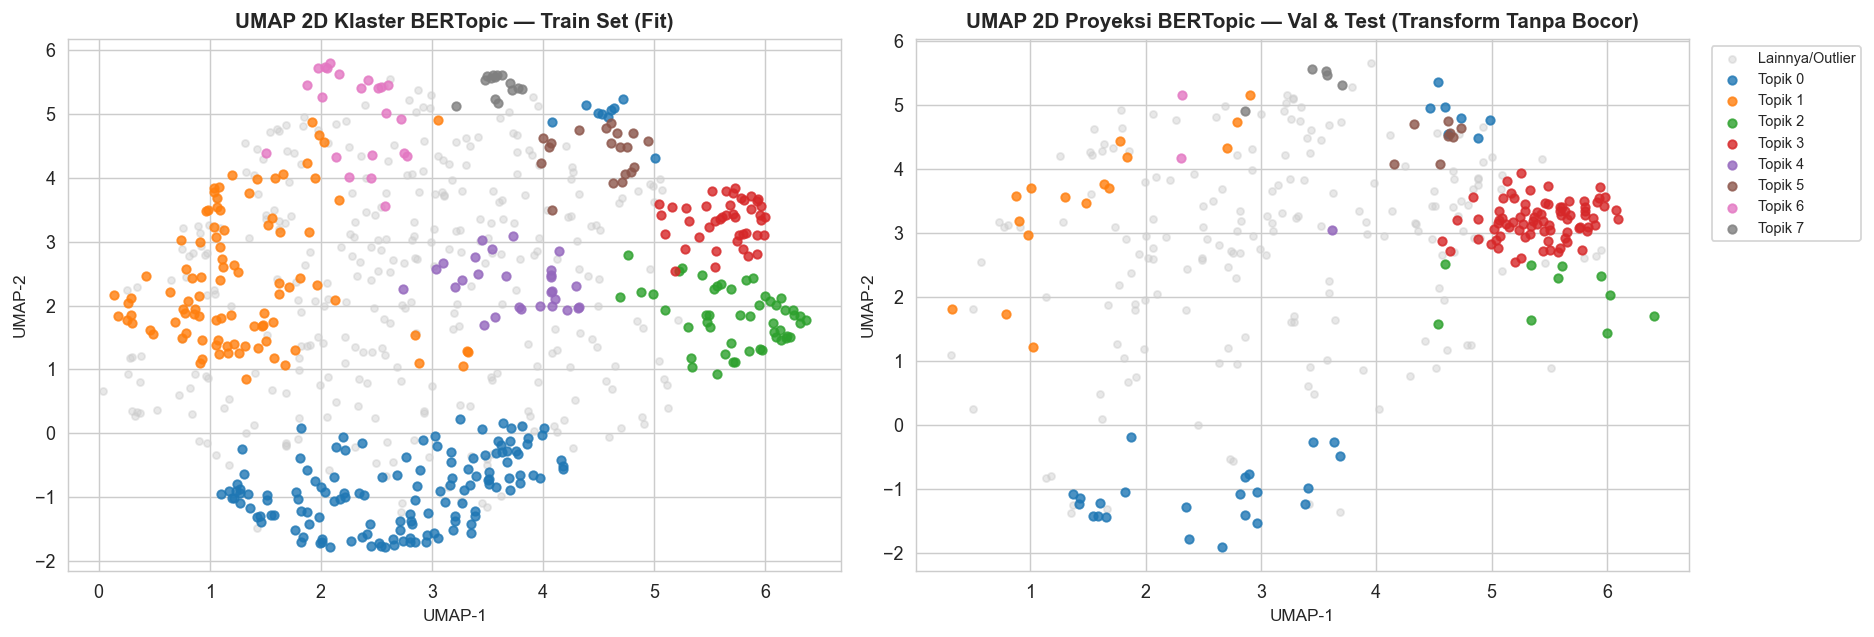

33219

In [5]:
try:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE, local_files_only=True)
except Exception:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
for p in st_model.parameters():
    p.requires_grad = False
st_model.eval()

daily_topic_docs = [
    f"{t}. {b[:500]}".strip() if hn == 1 else ""
    for t, b, hn in zip(df["title_clean"], df["norm_clean"], df["has_news"])
]
news_mask = df["has_news"].values == 1
tr_news_mask = is_tr & news_mask
news_docs_all = [d for d, m in zip(daily_topic_docs, news_mask) if m]

with torch.no_grad():
    news_embs_all = st_model.encode(news_docs_all, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

emb_minilm_full = np.zeros((len(df), news_embs_all.shape[1]), dtype=np.float32)
emb_minilm_full[news_mask] = news_embs_all

tr_docs = [daily_topic_docs[i] for i in np.where(tr_news_mask)[0]]
tr_embs = emb_minilm_full[tr_news_mask]

umap_bt = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
hdbscan_bt = HDBSCAN(min_cluster_size=15, min_samples=5, metric="euclidean", cluster_selection_method="eom", prediction_data=True)
vec_bt = CountVectorizer(stop_words="english", min_df=3, ngram_range=(1, 2))

topic_model = BERTopic(
    embedding_model=st_model,
    umap_model=umap_bt,
    hdbscan_model=hdbscan_bt,
    vectorizer_model=vec_bt,
    calculate_probabilities=True,
    verbose=False,
)
tr_topics, _ = topic_model.fit_transform(tr_docs, tr_embs)
bt_info = topic_model.get_topic_info()
print(f"BERTopic di-fit pada {len(tr_docs)} hari Train berberita -> {int((bt_info['Topic'] != -1).sum())} topik.")
display(bt_info.head(10))

all_news_topics, all_news_probs = topic_model.transform(news_docs_all, emb_minilm_full[news_mask])
all_news_probs = np.asarray(all_news_probs)
if all_news_probs.ndim == 1:
    uniq_t = sorted([t for t in set(tr_topics) if t != -1])
    oh = np.zeros((len(all_news_topics), max(len(uniq_t), 1)), dtype=np.float32)
    tmap = {t: j for j, t in enumerate(uniq_t)}
    for r_i, tv in enumerate(all_news_topics):
        if tv in tmap:
            oh[r_i, tmap[tv]] = 1.0
    all_news_probs = oh

topic_prob_full = np.zeros((len(df), all_news_probs.shape[1]), dtype=np.float32)
topic_prob_full[news_mask] = all_news_probs
df["bt_topic"] = -2
df.loc[news_mask, "bt_topic"] = all_news_topics

# Reduksi dimensi probabilitas topik dengan PCA (fit di Train)
TOPIC_PCA_DIM = min(5, topic_prob_full.shape[1])
sc_top = StandardScaler().fit(topic_prob_full[is_tr])
pca_top = PCA(n_components=TOPIC_PCA_DIM, random_state=SEED).fit(sc_top.transform(topic_prob_full[is_tr]))
top_pca = pca_top.transform(sc_top.transform(topic_prob_full))
topic_pca_cols = [f"topic_pca_{i}" for i in range(TOPIC_PCA_DIM)]
for i, c in enumerate(topic_pca_cols):
    df[c] = top_pca[:, i]

# Reduksi dimensi UMAP 2D (fit hanya di Train berberita)
umap_2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED).fit(tr_embs)
umap_2d_news = umap_2d.transform(emb_minilm_full[news_mask])
df["topic_umap_0"], df["topic_umap_1"] = 0.0, 0.0
df.loc[news_mask, "topic_umap_0"] = umap_2d_news[:, 0]
df.loc[news_mask, "topic_umap_1"] = umap_2d_news[:, 1]
topic_umap_cols = ["topic_umap_0", "topic_umap_1"]

# Plot UMAP 2D Train vs Val/Test
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5))
top_ids = bt_info[bt_info["Topic"] != -1]["Topic"].head(8).tolist()
cmap_t = {tid: sns.color_palette("tab10", len(top_ids))[i] for i, tid in enumerate(top_ids)}
for ax, mask_sub, title in [
    (axes[0], tr_news_mask, "UMAP 2D Klaster BERTopic — Train Set (Fit)"),
    (axes[1], (is_va | is_te) & news_mask, "UMAP 2D Proyeksi BERTopic — Val & Test (Transform Tanpa Bocor)"),
]:
    sub = df.loc[mask_sub]
    m_o = ~sub["bt_topic"].isin(top_ids)
    ax.scatter(sub.loc[m_o, "topic_umap_0"], sub.loc[m_o, "topic_umap_1"], c="#cccccc", s=15, alpha=0.45, label="Lainnya/Outlier")
    for tid in top_ids:
        mt = sub["bt_topic"] == tid
        if mt.sum() > 0:
            ax.scatter(sub.loc[mt, "topic_umap_0"], sub.loc[mt, "topic_umap_1"], color=cmap_t[tid], s=22, alpha=0.8, label=f"Topik {tid}")
    ax.set_title(title)
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

del st_model
gc.collect()


## 6. Stage 1: Classifier Arah Return (Gabungan BERT Title + Longformer FT + FinBERT + BERTopic)

Men-tuning classifier arah return (`1 = Kurs Naik`, `0 = Kurs Turun`) pada **Validation Set** lalu menghasilkan `pred_dir_prob` untuk **Train Set melalui 5-Fold OOF murni di dalam Train** (bebas *in-sample leakage*).


In [6]:
sent_s1_cols = [
    "kurs_pressure", "sent_polarity", "sent_magnitude", "sent_ratio",
    "finbert_pos", "finbert_neg", "finbert_neu", "has_news",
]

s1_grid = []
for n_b, n_l in [(4, 4), (8, 4), (4, 8), (8, 8)]:
    for c_v in [0.02, 0.05, 0.1, 0.2, 0.5]:
        s1_grid.append((
            f"LogReg(C={c_v}, b={n_b}, l={n_l})",
            n_b, n_l,
            lambda c=c_v: LogisticRegression(C=c, class_weight="balanced", max_iter=1000, random_state=SEED),
        ))
    for ne, md, lr_g in [(60, 2, 0.03), (100, 2, 0.03)]:
        s1_grid.append((
            f"GradBoost(n={ne}, d={md}, b={n_b}, l={n_l})",
            n_b, n_l,
            lambda n=ne, d=md, l=lr_g: GradientBoostingClassifier(n_estimators=n, max_depth=d, learning_rate=l, subsample=0.8, random_state=SEED),
        ))

s1_rows = []
for name, nb, nl, fac in s1_grid:
    cols_k = bert_pca_cols[:nb] + long_pca_cols[:nl] + sent_s1_cols + topic_pca_cols + topic_umap_cols
    sc_k = StandardScaler().fit(df.loc[is_tr, cols_k])
    clf_k = fac().fit(sc_k.transform(df.loc[is_tr, cols_k]), y_tr_dir)
    p_va = clf_k.predict_proba(sc_k.transform(df.loc[is_va, cols_k]))[:, 1]
    s1_rows.append({
        "Model": name, "nb": nb, "nl": nl,
        "Val Acc (%)": round(accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_va_dir, p_va), 4),
    })

s1_tune_df = pd.DataFrame(s1_rows).sort_values(["Val BalAcc (%)", "Val ROC-AUC"], ascending=False).reset_index(drop=True)
best_s1_name = s1_tune_df.iloc[0]["Model"]
best_nb, best_nl, best_s1_fac = next((nb, nl, fac) for nm, nb, nl, fac in s1_grid if nm == best_s1_name)
stage1_cols = bert_pca_cols[:best_nb] + long_pca_cols[:best_nl] + sent_s1_cols + topic_pca_cols + topic_umap_cols

print(f"Stage 1 Terbaik (Val): {best_s1_name} ({len(stage1_cols)} fitur)")
display(s1_tune_df.head(8))

# 5-Fold OOF di dalam Train untuk mencegah leakage ke Stage 2
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_tr_prob = np.zeros(len(y_tr_dir), dtype=np.float32)
for tr_f, ho_f in skf.split(df.loc[is_tr, stage1_cols], y_tr_dir):
    sc_f = StandardScaler().fit(df.loc[is_tr, stage1_cols].iloc[tr_f])
    clf_f = best_s1_fac().fit(sc_f.transform(df.loc[is_tr, stage1_cols].iloc[tr_f]), y_tr_dir[tr_f])
    oof_tr_prob[ho_f] = clf_f.predict_proba(sc_f.transform(df.loc[is_tr, stage1_cols].iloc[ho_f]))[:, 1]

sc_s1 = StandardScaler().fit(df.loc[is_tr, stage1_cols])
final_s1 = best_s1_fac().fit(sc_s1.transform(df.loc[is_tr, stage1_cols]), y_tr_dir)
p_s1_va = final_s1.predict_proba(sc_s1.transform(df.loc[is_va, stage1_cols]))[:, 1]
p_s1_te = final_s1.predict_proba(sc_s1.transform(df.loc[is_te, stage1_cols]))[:, 1]

df.loc[is_tr, "pred_dir_prob"] = oof_tr_prob
df.loc[is_va, "pred_dir_prob"] = p_s1_va
df.loc[is_te, "pred_dir_prob"] = p_s1_te
df["pred_dir_class"] = (df["pred_dir_prob"] >= 0.5).astype(int)
df["pred_dir_signed"] = 2.0 * df["pred_dir_prob"] - 1.0

s1_eval_df = pd.DataFrame([
    {"Split": "Train (5-Fold OOF)", "Acc (%)": round(accuracy_score(y_tr_dir, (oof_tr_prob >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_tr_dir, (oof_tr_prob >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_tr_dir, oof_tr_prob), 4)},
    {"Split": "Validation", "Acc (%)": round(accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_va_dir, p_s1_va), 4)},
    {"Split": "Test", "Acc (%)": round(accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_te_dir, p_s1_te), 4)},
])
display(s1_eval_df)


Stage 1 Terbaik (Val): LogReg(C=0.2, b=4, l=8) (27 fitur)


,Model,nb,nl,Val Acc (%),Val BalAcc (%),Val ROC-AUC
0,"LogReg(C=0.2, b=4, l=8)",4,8,56.67,57.44,0.5466
1,"LogReg(C=0.5, b=4, l=8)",4,8,55.56,56.18,0.5399
2,"LogReg(C=0.5, b=4, l=4)",4,4,55.56,56.10,0.5335
3,"LogReg(C=0.1, b=4, l=8)",4,8,55.00,55.80,0.5513
4,"LogReg(C=0.02, b=4, l=8)",4,8,54.44,55.21,0.5499
5,"LogReg(C=0.05, b=8, l=8)",8,8,54.44,55.06,0.5331
6,"LogReg(C=0.05, b=4, l=4)",4,4,54.44,54.99,0.5391
7,"LogReg(C=0.2, b=4, l=4)",4,4,54.44,54.99,0.5381


,Split,Acc (%),BalAcc (%),ROC-AUC
0,Train (5-Fold OOF),52.26,51.93,0.5515
1,Validation,56.67,57.44,0.5466
2,Test,56.91,55.93,0.5770


## 7. Fitur Interaksi `Sentimen × Arah` (Tinggi & Ekstrem — Penguatan Penurunan/Kenaikan Ekstrem)

Ambang kuantil dihitung **murni pada hari berberita di Train Set**:
- **Sentimen Tinggi (`HIGH_SENT_THRES` = kuantil ke-70 Train)**: `flag_naik_sent_tinggi`, `flag_turun_sent_tinggi`.
- **Sentimen Ekstrem (`EXTREME_SENT_THRES` = kuantil ke-90 Train)**:
  - `flag_naik_ekstrem`: prediksi Naik dengan sentimen negatif ekstrem (`sent_magnitude >= EXTREME_SENT_THRES`).
  - `flag_turun_ekstrem`: prediksi Turun dengan sentimen positif ekstrem $\rightarrow$ memberi sinyal penekanan kuat menuju **penurunan kurs yang ekstrem** (`extreme_turun_pressure = flag_turun_ekstrem * (-sent_magnitude)`).
  - `extreme_amp_x_dir`: amplifikasi non-linear $\text{sign}(\text{sent\_x\_dir}) \cdot |\text{sent\_x\_dir}|^2$.


Ambang Sentimen Tinggi  (Q70 Train): 0.6237
Ambang Sentimen Ekstrem (Q90 Train): 0.8493


,Split,Tier,Hari,Mean LogRet Aktual,Aktual Naik (%)
0,Train,-2: Ekstrem Turun,50,-0.000277,56.0
1,Train,-1: Tinggi Turun,90,-0.000196,44.4
2,Train,0: Netral/Rendah,621,0.000269,57.3
3,Train,+1: Tinggi Naik,56,-0.000124,50.0
4,Train,+2: Ekstrem Naik,23,-0.000156,56.5
5,Val,-2: Ekstrem Turun,22,-0.000140,59.1
6,Val,-1: Tinggi Turun,21,-0.000000,28.6
7,Val,0: Netral/Rendah,127,0.000386,58.3
8,Val,+1: Tinggi Naik,6,-0.001567,33.3
9,Val,+2: Ekstrem Naik,4,-0.001022,25.0


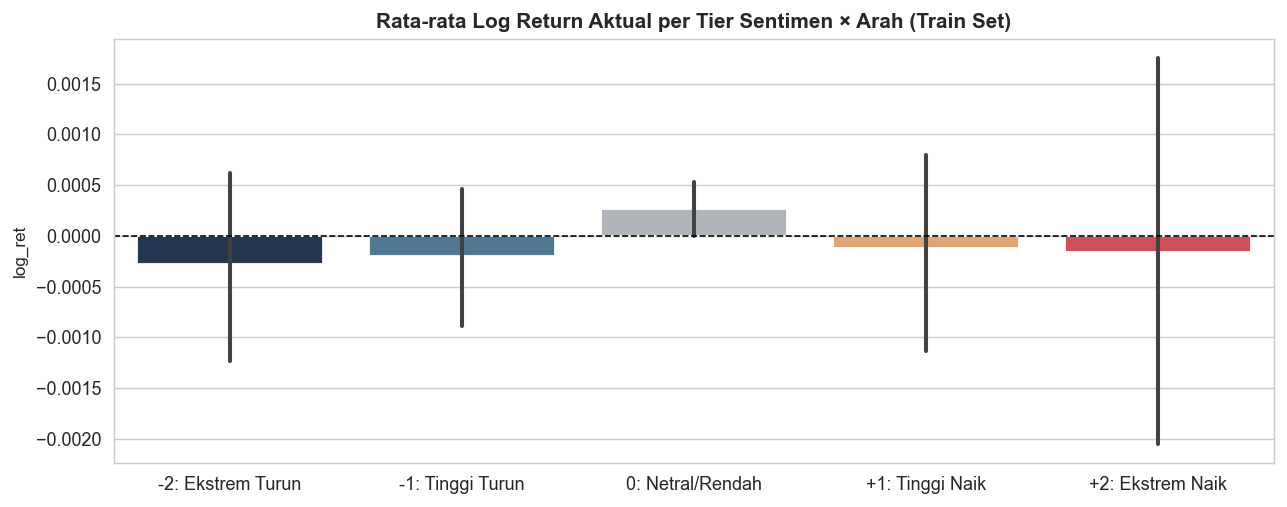

In [7]:
tr_mags = df.loc[is_tr & (df["has_news"] == 1), "sent_magnitude"].values
HIGH_SENT_THRES = float(np.quantile(tr_mags, 0.70))
EXTREME_SENT_THRES = float(np.quantile(tr_mags, 0.90))
print(f"Ambang Sentimen Tinggi  (Q70 Train): {HIGH_SENT_THRES:.4f}")
print(f"Ambang Sentimen Ekstrem (Q90 Train): {EXTREME_SENT_THRES:.4f}")

df["sent_x_dir"] = df["kurs_pressure"] * df["pred_dir_signed"]
df["sent_mag_x_dir"] = df["sent_magnitude"] * df["pred_dir_signed"]
df["extreme_amp_x_dir"] = np.sign(df["sent_x_dir"]) * (np.abs(df["sent_x_dir"]) ** 2)

is_high = df["sent_magnitude"] >= HIGH_SENT_THRES
is_ext = df["sent_magnitude"] >= EXTREME_SENT_THRES

df["flag_naik_sent_tinggi"] = ((df["pred_dir_class"] == 1) & is_high).astype(int)
df["flag_turun_sent_tinggi"] = ((df["pred_dir_class"] == 0) & is_high).astype(int)
df["flag_naik_ekstrem"] = ((df["pred_dir_class"] == 1) & is_ext).astype(int)
df["flag_turun_ekstrem"] = ((df["pred_dir_class"] == 0) & is_ext).astype(int)

# Sinyal khusus amplifikasi ekstrem ke penurunan & kenaikan
df["extreme_turun_pressure"] = df["flag_turun_ekstrem"] * (-df["sent_magnitude"])
df["extreme_naik_pressure"] = df["flag_naik_ekstrem"] * (df["sent_magnitude"])

# 5 Tier: -2 (Ekstrem Turun), -1 (Tinggi Turun), 0 (Netral/Rendah), +1 (Tinggi Naik), +2 (Ekstrem Naik)
df["sent_dir_5tier"] = (
    df["flag_naik_sent_tinggi"] + df["flag_naik_ekstrem"]
    - df["flag_turun_sent_tinggi"] - df["flag_turun_ekstrem"]
)
tier5_map = {
    -2: "-2: Ekstrem Turun",
    -1: "-1: Tinggi Turun",
    0: "0: Netral/Rendah",
    1: "+1: Tinggi Naik",
    2: "+2: Ekstrem Naik",
}
df["sent_dir_5tier_label"] = df["sent_dir_5tier"].map(tier5_map)

tier_rows = []
for sp_n, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    for tv in [-2, -1, 0, 1, 2]:
        g = sub[sub["sent_dir_5tier"] == tv]
        tier_rows.append({
            "Split": sp_n,
            "Tier": tier5_map[tv],
            "Hari": len(g),
            "Mean LogRet Aktual": round(float(g["log_ret"].mean()), 6) if len(g) > 0 else np.nan,
            "Aktual Naik (%)": round(float(g["y_dir"].mean() * 100), 1) if len(g) > 0 else np.nan,
        })
display(pd.DataFrame(tier_rows))

fig, ax = plt.subplots(figsize=(10, 4))
order_5 = [tier5_map[k] for k in [-2, -1, 0, 1, 2]]
sns.barplot(data=df.loc[is_tr], x="sent_dir_5tier_label", y="log_ret", order=order_5,
            palette=["#1d3557", "#457b9d", "#adb5bd", "#f4a261", "#e63946"], ax=ax)
ax.axhline(0, color="black", linestyle="--", lw=0.9)
ax.set_title("Rata-rata Log Return Aktual per Tier Sentimen × Arah (Train Set)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()


## 8. Penggabungan dengan Fitur Time Series (Strictly Causal $\le t-1$) & Definisi Kelompok Fitur

Menyusun 14 fitur *time series* (*lagged return*, volatilitas *rolling*, deviasi MA5/10/20, RSI 14, *streak* naik/turun, spread, dan hari perdagangan) serta mengelompokkan fitur secara eksplisit untuk **Studi Ablasi**.


In [8]:
df["ret_lag1"] = df["log_ret"].shift(1)
df["ret_lag2"] = df["log_ret"].shift(2)
df["ret_lag3"] = df["log_ret"].shift(3)
df["ret_lag5"] = df["log_ret"].shift(5)
df["vol_5d"] = df["log_ret"].shift(1).rolling(5).std()
df["vol_10d"] = df["log_ret"].shift(1).rolling(10).std()

for w in [5, 10, 20]:
    ma_w = df["rate_mid"].shift(1).rolling(w).mean()
    df[f"dist_ma{w}"] = df["rate_mid"].shift(1) / ma_w - 1.0

delta = df["rate_mid"].diff().shift(1)
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
df["rsi_14"] = (100.0 - (100.0 / (1.0 + gain / (loss + 1e-9)))) / 100.0

consecs, cur = [], 0
for r in df["log_ret"]:
    cur = (cur + 1 if cur > 0 else 1) if r > 0 else ((cur - 1 if cur < 0 else -1) if r < 0 else 0)
    consecs.append(cur)
df["consec_up_days"] = pd.Series(consecs, index=df.index).shift(1)
df["spread_lag1"] = ((df["Kurs Jual"] - df["Kurs Beli"]) / df["rate_mid"]).shift(1)
dow = df[date_col].dt.dayofweek
df["dow_sin"] = np.sin(2 * np.pi * dow / 5.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 5.0)

# Definisi 5 kelompok fitur untuk studi ablasi & pemodelan
GRP_TS = [
    "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5",
    "vol_5d", "vol_10d", "dist_ma5", "dist_ma10", "dist_ma20",
    "rsi_14", "consec_up_days", "spread_lag1", "dow_sin", "dow_cos",
]
GRP_BERT_TITLE = bert_pca_cols[:4]
GRP_LONGFORMER = long_pca_cols[:4]
GRP_FINBERT_SENT = [
    "kurs_pressure", "sent_magnitude", "has_news",
    "pred_dir_prob", "pred_dir_signed",
    "sent_x_dir", "sent_mag_x_dir", "extreme_amp_x_dir",
    "flag_naik_sent_tinggi", "flag_turun_sent_tinggi",
    "flag_naik_ekstrem", "flag_turun_ekstrem",
    "extreme_turun_pressure", "extreme_naik_pressure", "sent_dir_5tier",
]
GRP_BERTOPIC = topic_pca_cols + topic_umap_cols

FULL_COLS = GRP_TS + GRP_BERT_TITLE + GRP_LONGFORMER + GRP_FINBERT_SENT + GRP_BERTOPIC
df_model = df.dropna(subset=FULL_COLS + ["log_ret"]).reset_index(drop=True)

m_tr = (df_model[date_col] <= train_end_date).values
m_va = ((df_model[date_col] > train_end_date) & (df_model[date_col] <= val_end_date)).values
m_te = (df_model[date_col] > val_end_date).values

print(f"Baris valid Stage 2: {len(df_model):,} | Train={m_tr.sum()}, Val={m_va.sum()}, Test={m_te.sum()}")
print(f"Ringkasan jumlah fitur ({len(FULL_COLS)} total): TS={len(GRP_TS)}, BERT-Title={len(GRP_BERT_TITLE)}, Longformer-FT={len(GRP_LONGFORMER)}, FinBERT+Sent×Arah={len(GRP_FINBERT_SENT)}, BERTopic={len(GRP_BERTOPIC)}")

def build_sequences(frame: pd.DataFrame, feature_cols: list[str], seq_len: int):
    sc_x = StandardScaler().fit(frame.loc[m_tr, feature_cols])
    X_scaled = sc_x.transform(frame[feature_cols]).astype(np.float32)
    y_raw = frame["log_ret"].values.astype(np.float32)
    mu_y = float(y_raw[m_tr].mean())
    std_y = float(y_raw[m_tr].std() + 1e-9)
    y_scaled = ((y_raw - mu_y) / std_y).astype(np.float32)

    X_seqs, y_seqs_s, y_seqs_raw, seq_splits, seq_dates, prev_rates, curr_rates = [], [], [], [], [], [], []
    split_arr = np.where(m_tr, "train", np.where(m_va, "val", "test"))
    dates_arr = frame[date_col].values
    rates_arr = frame["rate_mid"].values

    for t in range(seq_len - 1, len(frame)):
        X_seqs.append(X_scaled[t - seq_len + 1 : t + 1])
        y_seqs_s.append(y_scaled[t])
        y_seqs_raw.append(y_raw[t])
        seq_splits.append(split_arr[t])
        seq_dates.append(dates_arr[t])
        prev_rates.append(rates_arr[t - 1])
        curr_rates.append(rates_arr[t])

    return {
        "X": np.array(X_seqs, dtype=np.float32),
        "y_s": np.array(y_seqs_s, dtype=np.float32),
        "y_raw": np.array(y_seqs_raw, dtype=np.float32),
        "split": np.array(seq_splits),
        "dates": pd.to_datetime(seq_dates),
        "prev_rate": np.array(prev_rates, dtype=np.float64),
        "curr_rate": np.array(curr_rates, dtype=np.float64),
        "mu_y": mu_y,
        "std_y": std_y,
    }


Baris valid Stage 2: 1,181 | Train=820, Val=180, Test=181
Ringkasan jumlah fitur (44 total): TS=14, BERT-Title=4, Longformer-FT=4, FinBERT+Sent×Arah=15, BERTopic=7


## 9. Pemodelan Neural (MLP, LSTM, Bi-LSTM) & Hyperparameter Tuning Model Terbaik

Melatih dan men-tuning **MLP**, **LSTM** (*unidirectional*), dan **Bi-LSTM** (*bidirectional*) pada **Validation Set**, lalu melakukan **Fine-Grained Hyperparameter Tuning** pada arsitektur terbaik sebelum mengevaluasinya pada **Test Set**.


In [9]:
class TabularMLPRegressor(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32, dropout: float = 0.35):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 16),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class SeqLSTMRegressor(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32, num_layers: int = 1,
                 dropout: float = 0.35, bidirectional: bool = True):
        super().__init__()
        self.in_norm = nn.LayerNorm(input_dim)
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.head = nn.Sequential(
            nn.LayerNorm(out_dim),
            nn.Dropout(dropout),
            nn.Linear(out_dim, 16),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        x = self.in_norm(x)
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_pytorch_regressor(model: nn.Module, X_tr_np, y_tr_s_np, X_va_np, y_va_s_np, X_te_np,
                            mu_y: float, std_y: float, lr: float = 1e-3, weight_decay: float = 1e-3,
                            dir_lambda: float = 0.15, batch_size: int = 32, epochs: int = 70, patience: int = 12):
    set_seed(SEED)
    X_tr = torch.tensor(X_tr_np, dtype=torch.float32)
    y_tr = torch.tensor(y_tr_s_np, dtype=torch.float32)
    X_va = torch.tensor(X_va_np, dtype=torch.float32).to(DEVICE)
    y_va = torch.tensor(y_va_s_np, dtype=torch.float32).to(DEVICE)
    X_te = torch.tensor(X_te_np, dtype=torch.float32).to(DEVICE)

    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    def composite_loss(pred_s, target_s):
        mse = nn.functional.mse_loss(pred_s, target_s)
        zero_s = -mu_y / std_y
        sign_hinge = torch.relu(-(pred_s - zero_s) * torch.sign(target_s - zero_s)).mean()
        return mse + dir_lambda * sign_hinge

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    wait = 0
    tr_hist, va_hist = [], []

    for _ in range(epochs):
        model.train()
        ep_losses = []
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = composite_loss(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            ep_losses.append(float(loss.item()))

        model.eval()
        with torch.no_grad():
            va_loss = float(composite_loss(model(X_va), y_va).item())

        tr_hist.append(float(np.mean(ep_losses)))
        va_hist.append(va_loss)

        if va_loss < best_val_loss - 1e-6:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_va_raw = model(X_va).cpu().numpy() * std_y + mu_y
        pred_te_raw = model(X_te).cpu().numpy() * std_y + mu_y

    return {
        "pred_va": pred_va_raw,
        "pred_te": pred_te_raw,
        "tr_hist": tr_hist,
        "va_hist": va_hist,
        "best_epoch": len(tr_hist) - wait,
    }


def eval_reg(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    dt, dp = (y_true > 0).astype(int), (y_pred > 0).astype(int)
    return {
        "Model": name,
        "RMSE": round(rmse, 6),
        "MAE": round(mae, 6),
        "R2": round(r2, 4),
        "DirAcc (%)": round(float(accuracy_score(dt, dp) * 100), 2),
        "BalAcc (%)": round(float(balanced_accuracy_score(dt, dp) * 100), 2),
    }

seq_full_cache = {sl: build_sequences(df_model, FULL_COLS, sl) for sl in [5, 10, 15]}
b10 = seq_full_cache[10]
sp10 = b10["split"]
X_tab_tr, X_tab_va, X_tab_te = b10["X"][sp10 == "train"][:, -1, :], b10["X"][sp10 == "val"][:, -1, :], b10["X"][sp10 == "test"][:, -1, :]
y_tab_tr_s, y_va_s = b10["y_s"][sp10 == "train"], b10["y_s"][sp10 == "val"]
y_va_true, y_te_true = b10["y_raw"][sp10 == "val"], b10["y_raw"][sp10 == "test"]
mu_y_b, std_y_b = b10["mu_y"], b10["std_y"]

# 1) Tuning MLP
mlp_grid = [
    {"hidden_dim": 16, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"hidden_dim": 32, "dropout": 0.35, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"hidden_dim": 32, "dropout": 0.45, "lr": 5e-4, "dir_lambda": 0.25, "weight_decay": 2e-3},
    {"hidden_dim": 64, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"hidden_dim": 32, "dropout": 0.30, "lr": 1e-3, "dir_lambda": 0.00, "weight_decay": 2e-3},
    {"hidden_dim": 64, "dropout": 0.45, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 3e-3},
]
mlp_rows, mlp_runs = [], []
for cid, cfg in enumerate(mlp_grid):
    r = train_pytorch_regressor(
        TabularMLPRegressor(X_tab_tr.shape[1], hidden_dim=cfg["hidden_dim"], dropout=cfg["dropout"]),
        X_tab_tr, y_tab_tr_s, X_tab_va, y_va_s, X_tab_te,
        mu_y_b, std_y_b, lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
    )
    m = eval_reg(f"MLP #{cid}", y_va_true, r["pred_va"])
    mlp_rows.append({"arch": "MLP", "cfg_id": cid, **cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
    mlp_runs.append(r)

# 2) Tuning LSTM & Bi-LSTM
seq_grid = [
    {"seq_len": 5,  "hidden_dim": 16, "num_layers": 1, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"seq_len": 5,  "hidden_dim": 32, "num_layers": 1, "dropout": 0.35, "lr": 1e-3, "dir_lambda": 0.25, "weight_decay": 1e-3},
    {"seq_len": 10, "hidden_dim": 16, "num_layers": 1, "dropout": 0.35, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 10, "hidden_dim": 32, "num_layers": 1, "dropout": 0.30, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"seq_len": 10, "hidden_dim": 32, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 2e-3},
    {"seq_len": 10, "hidden_dim": 64, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 15, "hidden_dim": 32, "num_layers": 1, "dropout": 0.35, "lr": 5e-4, "dir_lambda": 0.25, "weight_decay": 2e-3},
    {"seq_len": 15, "hidden_dim": 64, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 3e-3},
]

def tune_seq_arch(bidir: bool, arch_name: str):
    rows, runs = [], []
    for cid, cfg in enumerate(seq_grid):
        b = seq_full_cache[cfg["seq_len"]]
        sp = b["split"]
        tr_i, va_i, te_i = sp == "train", sp == "val", sp == "test"
        r = train_pytorch_regressor(
            SeqLSTMRegressor(b["X"].shape[2], cfg["hidden_dim"], cfg["num_layers"], cfg["dropout"], bidirectional=bidir),
            b["X"][tr_i], b["y_s"][tr_i], b["X"][va_i], b["y_s"][va_i], b["X"][te_i],
            b["mu_y"], b["std_y"], lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
        )
        m = eval_reg(f"{arch_name} #{cid}", b["y_raw"][va_i], r["pred_va"])
        rows.append({"arch": arch_name, "cfg_id": cid, **cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
        runs.append(r)
    return rows, runs

lstm_rows, lstm_runs = tune_seq_arch(False, "LSTM")
bilstm_rows, bilstm_runs = tune_seq_arch(True, "Bi-LSTM")

def pick_best(rows, runs):
    d = pd.DataFrame(rows)
    d["Val Score"] = (d["Val BalAcc (%)"] - 2500.0 * (d["Val RMSE"] - d["Val RMSE"].min())).round(3)
    d = d.sort_values("Val Score", ascending=False).reset_index(drop=True)
    cid = int(d.iloc[0]["cfg_id"])
    return d, runs[cid], d.iloc[0].to_dict()

mlp_df, res_mlp_best, best_mlp_meta = pick_best(mlp_rows, mlp_runs)
lstm_df, res_lstm_best, best_lstm_meta = pick_best(lstm_rows, lstm_runs)
bilstm_df, res_bilstm_best, best_bilstm_meta = pick_best(bilstm_rows, bilstm_runs)

# Pilih arsitektur terbaik berdasarkan Validation Score
arch_ranking = pd.DataFrame([best_mlp_meta, best_lstm_meta, best_bilstm_meta])
arch_ranking["Val Score"] = (arch_ranking["Val BalAcc (%)"] - 2500.0 * (arch_ranking["Val RMSE"] - arch_ranking["Val RMSE"].min())).round(3)
arch_ranking = arch_ranking.sort_values("Val Score", ascending=False).reset_index(drop=True)
best_arch_name = arch_ranking.iloc[0]["arch"]
print(f"Arsitektur terbaik pada Validation Set: {best_arch_name}")
display(arch_ranking[["arch", "Val RMSE", "Val DirAcc (%)", "Val BalAcc (%)", "Val Score", "best_epoch"]])

# --- Fine-Grained Hyperparameter Tuning Lanjutan untuk Model Terbaik ---
best_meta_row = arch_ranking.iloc[0]
fine_rows, fine_runs, fine_cfgs = [], [], []
if best_arch_name == "MLP":
    base_hd = int(best_meta_row["hidden_dim"])
    for hd in sorted({max(16, base_hd // 2), base_hd, min(64, base_hd * 2)}):
        for dr in [0.25, 0.35, 0.45]:
            for dl in [0.10, 0.25]:
                for lr_v in [5e-4, 1e-3]:
                    cfg = {"hidden_dim": hd, "dropout": dr, "dir_lambda": dl, "lr": lr_v, "weight_decay": 2e-3, "batch_size": 32}
                    r = train_pytorch_regressor(
                        TabularMLPRegressor(X_tab_tr.shape[1], hd, dr),
                        X_tab_tr, y_tab_tr_s, X_tab_va, y_va_s, X_tab_te,
                        mu_y_b, std_y_b, lr=lr_v, weight_decay=2e-3, dir_lambda=dl,
                    )
                    m = eval_reg("fine", y_va_true, r["pred_va"])
                    fine_rows.append({**cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
                    fine_runs.append(r)
                    fine_cfgs.append(cfg)
else:
    bidir_flag = (best_arch_name == "Bi-LSTM")
    base_sl = int(best_meta_row["seq_len"])
    base_hd = int(best_meta_row["hidden_dim"])
    for sl in sorted({max(5, base_sl - 5), base_sl, min(15, base_sl + 5)}):
        b = seq_full_cache[sl]
        sp = b["split"]
        tr_i, va_i, te_i = sp == "train", sp == "val", sp == "test"
        for hd in sorted({base_hd, 32, 64}):
            for dr in [0.30, 0.40]:
                for dl in [0.15, 0.30]:
                    cfg = {"seq_len": sl, "hidden_dim": hd, "num_layers": 1, "dropout": dr, "dir_lambda": dl, "lr": float(best_meta_row["lr"]), "weight_decay": 2e-3}
                    r = train_pytorch_regressor(
                        SeqLSTMRegressor(b["X"].shape[2], hd, 1, dr, bidirectional=bidir_flag),
                        b["X"][tr_i], b["y_s"][tr_i], b["X"][va_i], b["y_s"][va_i], b["X"][te_i],
                        b["mu_y"], b["std_y"], lr=cfg["lr"], weight_decay=2e-3, dir_lambda=dl,
                    )
                    m = eval_reg("fine", b["y_raw"][va_i], r["pred_va"])
                    fine_rows.append({**cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
                    fine_runs.append(r)
                    fine_cfgs.append(cfg)

fine_df = pd.DataFrame(fine_rows)
fine_df["Val Score"] = (fine_df["Val BalAcc (%)"] - 2500.0 * (fine_df["Val RMSE"] - fine_df["Val RMSE"].min())).round(3)
fine_df = fine_df.sort_values("Val Score", ascending=False).reset_index(drop=True)
best_fine_idx = int(fine_df.index[0])
# Ambil indeks asli sebelum sort
orig_best_idx = int(pd.DataFrame(fine_rows).assign(Val_Score=lambda x: x["Val BalAcc (%)"] - 2500.0 * (x["Val RMSE"] - x["Val RMSE"].min())).sort_values("Val_Score", ascending=False).index[0])
res_best_tuned = fine_runs[orig_best_idx]
best_fine_cfg = fine_cfgs[orig_best_idx]

print(f"\nFine-Tuned {best_arch_name} Terbaik ({len(fine_rows)} kombinasi di Val): {best_fine_cfg} (epoch={res_best_tuned['best_epoch']})")
display(fine_df.head(6))

# Evaluasi perbandingan MLP vs LSTM vs Bi-LSTM vs Fine-Tuned Best Model di Test Set
mu_train_raw = float(b10["y_raw"][sp10 == "train"].mean())
neural_test_df = pd.DataFrame([
    eval_reg("Baseline: Tebak Return 0", y_te_true, np.zeros_like(y_te_true)),
    eval_reg("Baseline: Mean Train", y_te_true, np.full_like(y_te_true, mu_train_raw)),
    eval_reg("Tuned MLP (Multimodal)", y_te_true, res_mlp_best["pred_te"]),
    eval_reg("Tuned LSTM (Multimodal)", y_te_true, res_lstm_best["pred_te"]),
    eval_reg("Tuned Bi-LSTM (Multimodal)", y_te_true, res_bilstm_best["pred_te"]),
    eval_reg(f"Fine-Tuned Best ({best_arch_name})", y_te_true, res_best_tuned["pred_te"]),
]).set_index("Model")

print("\n=== PERBANDINGAN MLP vs LSTM vs Bi-LSTM & FINE-TUNED MODEL (TEST SET) ===")
display(neural_test_df)


Arsitektur terbaik pada Validation Set: Bi-LSTM


,arch,Val RMSE,Val DirAcc (%),Val BalAcc (%),Val Score,best_epoch
0,Bi-LSTM,0.003334,55.56,54.91,54.86,5
1,LSTM,0.003314,55.56,54.84,54.84,10
2,MLP,0.003374,53.33,52.23,52.08,2



Fine-Tuned Bi-LSTM Terbaik (16 kombinasi di Val): {'seq_len': 10, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.3, 'dir_lambda': 0.3, 'lr': 0.0005, 'weight_decay': 0.002} (epoch=4)


,seq_len,hidden_dim,num_layers,dropout,dir_lambda,lr,weight_decay,Val RMSE,Val BalAcc (%),Val DirAcc (%),best_epoch,Val Score
0,10,64,1,0.3,0.30,0.0005,0.002,0.003365,58.11,58.33,4,57.992
1,10,32,1,0.4,0.30,0.0005,0.002,0.003361,54.91,55.56,11,54.802
2,15,32,1,0.3,0.30,0.0005,0.002,0.003318,54.69,55.56,6,54.690
3,15,32,1,0.4,0.15,0.0005,0.002,0.003334,53.42,54.44,10,53.380
4,10,32,1,0.4,0.15,0.0005,0.002,0.003332,53.35,53.89,8,53.315
5,10,64,1,0.4,0.30,0.0005,0.002,0.003339,53.05,53.33,4,52.997



=== PERBANDINGAN MLP vs LSTM vs Bi-LSTM & FINE-TUNED MODEL (TEST SET) ===


,RMSE,MAE,R2,DirAcc (%),BalAcc (%)
Model,,,,,
Baseline: Tebak Return 0,0.002902,0.002201,-0.0125,42.54,50.00
Baseline: Mean Train,0.002888,0.002178,-0.0031,57.46,50.00
Tuned MLP (Multimodal),0.002859,0.002151,0.0167,56.35,53.25
Tuned LSTM (Multimodal),0.002900,0.002174,-0.0111,53.04,51.21
Tuned Bi-LSTM (Multimodal),0.002905,0.002178,-0.0148,58.56,56.19
Fine-Tuned Best (Bi-LSTM),0.002922,0.002205,-0.0265,54.14,51.50


## 10. Studi Ablasi Fitur Menyeluruh (Menemukan Fitur yang Paling Berpengaruh)

Menggunakan arsitektur & konfigurasi terbaik hasil tuning (`best_arch_name` & `best_fine_cfg`) untuk menguji kontribusi masing-masing kelompok fitur secara adil (fit murni di Train $\to$ evaluasi di Test):
1. **Ablasi Aditif (Additive)**: melihat peningkatan dari `TS Only` menuju `Full Multimodal`.
2. **Ablasi Leave-One-Group-Out (LOGO)**: menghapus 1 kelompok fitur dari `Full Multimodal` untuk menghitung $\Delta \text{RMSE}$ dan $\Delta \text{BalAcc}$ sehingga terlihat **kelompok fitur mana yang paling berpengaruh**.


In [10]:
def eval_feature_subset(subset_name: str, cols_subset: list[str]):
    if best_arch_name == "MLP":
        b = build_sequences(df_model, cols_subset, 10)
        sp = b["split"]
        r = train_pytorch_regressor(
            TabularMLPRegressor(len(cols_subset), best_fine_cfg["hidden_dim"], best_fine_cfg["dropout"]),
            b["X"][sp == "train"][:, -1, :], b["y_s"][sp == "train"],
            b["X"][sp == "val"][:, -1, :], b["y_s"][sp == "val"],
            b["X"][sp == "test"][:, -1, :],
            b["mu_y"], b["std_y"],
            lr=best_fine_cfg["lr"], weight_decay=best_fine_cfg["weight_decay"], dir_lambda=best_fine_cfg["dir_lambda"],
        )
    else:
        b = build_sequences(df_model, cols_subset, best_fine_cfg["seq_len"])
        sp = b["split"]
        r = train_pytorch_regressor(
            SeqLSTMRegressor(len(cols_subset), best_fine_cfg["hidden_dim"], 1, best_fine_cfg["dropout"], bidirectional=(best_arch_name == "Bi-LSTM")),
            b["X"][sp == "train"], b["y_s"][sp == "train"],
            b["X"][sp == "val"], b["y_s"][sp == "val"],
            b["X"][sp == "test"],
            b["mu_y"], b["std_y"],
            lr=best_fine_cfg["lr"], weight_decay=best_fine_cfg["weight_decay"], dir_lambda=best_fine_cfg["dir_lambda"],
        )
    y_t = b["y_raw"][b["split"] == "test"]
    return {**eval_reg(subset_name, y_t, r["pred_te"]), "n_fitur": len(cols_subset)}

# 1. Additive Ablation
additive_configs = [
    ("1. TS Only", GRP_TS),
    ("2. TS + BERT Title", GRP_TS + GRP_BERT_TITLE),
    ("3. TS + Longformer Full-Text", GRP_TS + GRP_LONGFORMER),
    ("4. TS + BERT Title + Longformer", GRP_TS + GRP_BERT_TITLE + GRP_LONGFORMER),
    ("5. TS + FinBERT & Sent×Arah (Tinggi+Ekstrem)", GRP_TS + GRP_FINBERT_SENT),
    ("6. TS + BERTopic (PCA/UMAP)", GRP_TS + GRP_BERTOPIC),
    ("7. Full Multimodal (Lengkap)", FULL_COLS),
]
ablation_add_df = pd.DataFrame([eval_feature_subset(n, c) for n, c in additive_configs]).set_index("Model")
print("=== STUDI ABLASI ADITIF (TEST SET) ===")
display(ablation_add_df)

# 2. Leave-One-Group-Out (LOGO) Ablation
full_rmse = float(ablation_add_df.loc["7. Full Multimodal (Lengkap)", "RMSE"])
full_bal = float(ablation_add_df.loc["7. Full Multimodal (Lengkap)", "BalAcc (%)"])

logo_configs = [
    ("Tanpa Time Series", [c for c in FULL_COLS if c not in GRP_TS]),
    ("Tanpa BERT Title", [c for c in FULL_COLS if c not in GRP_BERT_TITLE]),
    ("Tanpa Longformer Full-Text", [c for c in FULL_COLS if c not in GRP_LONGFORMER]),
    ("Tanpa FinBERT & Sent×Arah", [c for c in FULL_COLS if c not in GRP_FINBERT_SENT]),
    ("Tanpa BERTopic", [c for c in FULL_COLS if c not in GRP_BERTOPIC]),
]
logo_rows = []
for lbl, cols_minus in logo_configs:
    res_l = eval_feature_subset(lbl, cols_minus)
    res_l["Delta RMSE (tanpa - full)"] = round(res_l["RMSE"] - full_rmse, 6)
    res_l["Delta BalAcc (full - tanpa)"] = round(full_bal - res_l["BalAcc (%)"], 2)
    logo_rows.append(res_l)

logo_df = pd.DataFrame(logo_rows).set_index("Model").sort_values("Delta BalAcc (full - tanpa)", ascending=False)
print("\n=== STUDI ABLASI LEAVE-ONE-GROUP-OUT (PENGARUH KELOMPOK FITUR) ===")
print("Catatan: Delta > 0 berarti menghapus kelompok fitur tersebut memperburuk performa (fitur sangat berpengaruh).")
display(logo_df)


=== STUDI ABLASI ADITIF (TEST SET) ===


,RMSE,MAE,R2,DirAcc (%),BalAcc (%),n_fitur
Model,,,,,,
1. TS Only,0.002919,0.002205,-0.0248,55.25,52.46,14
2. TS + BERT Title,0.002956,0.002248,-0.0509,47.51,47.25,18
3. TS + Longformer Full-Text,0.002959,0.002220,-0.0529,49.17,48.52,18
4. TS + BERT Title + Longformer,0.002907,0.002194,-0.0160,54.14,51.33,22
5. TS + FinBERT & Sent×Arah (Tinggi+Ekstrem),0.002891,0.002191,-0.0053,54.70,53.33,29
6. TS + BERTopic (PCA/UMAP),0.002881,0.002161,0.0015,54.70,51.81,21
7. Full Multimodal (Lengkap),0.002907,0.002195,-0.0163,55.25,53.81,44



=== STUDI ABLASI LEAVE-ONE-GROUP-OUT (PENGARUH KELOMPOK FITUR) ===
Catatan: Delta > 0 berarti menghapus kelompok fitur tersebut memperburuk performa (fitur sangat berpengaruh).


,RMSE,MAE,R2,DirAcc (%),BalAcc (%),n_fitur,Delta RMSE (tanpa - full),Delta BalAcc (full - tanpa)
Model,,,,,,,,
Tanpa BERTopic,0.002893,0.002159,-0.0067,53.04,50.37,37,-0.000014,3.44
Tanpa FinBERT & Sent×Arah,0.002879,0.002187,0.0029,53.04,51.89,29,-0.000028,1.92
Tanpa Longformer Full-Text,0.002899,0.002153,-0.0105,54.70,52.32,40,-0.000008,1.49
Tanpa BERT Title,0.002901,0.002202,-0.0124,54.14,53.52,40,-0.000006,0.29
Tanpa Time Series,0.002919,0.002152,-0.0247,62.43,61.24,30,0.000012,-7.43


## 11. Visualisasi Akhir: Studi Ablasi, Perbandingan Model, & Rekonstruksi Kurs USD/IDR


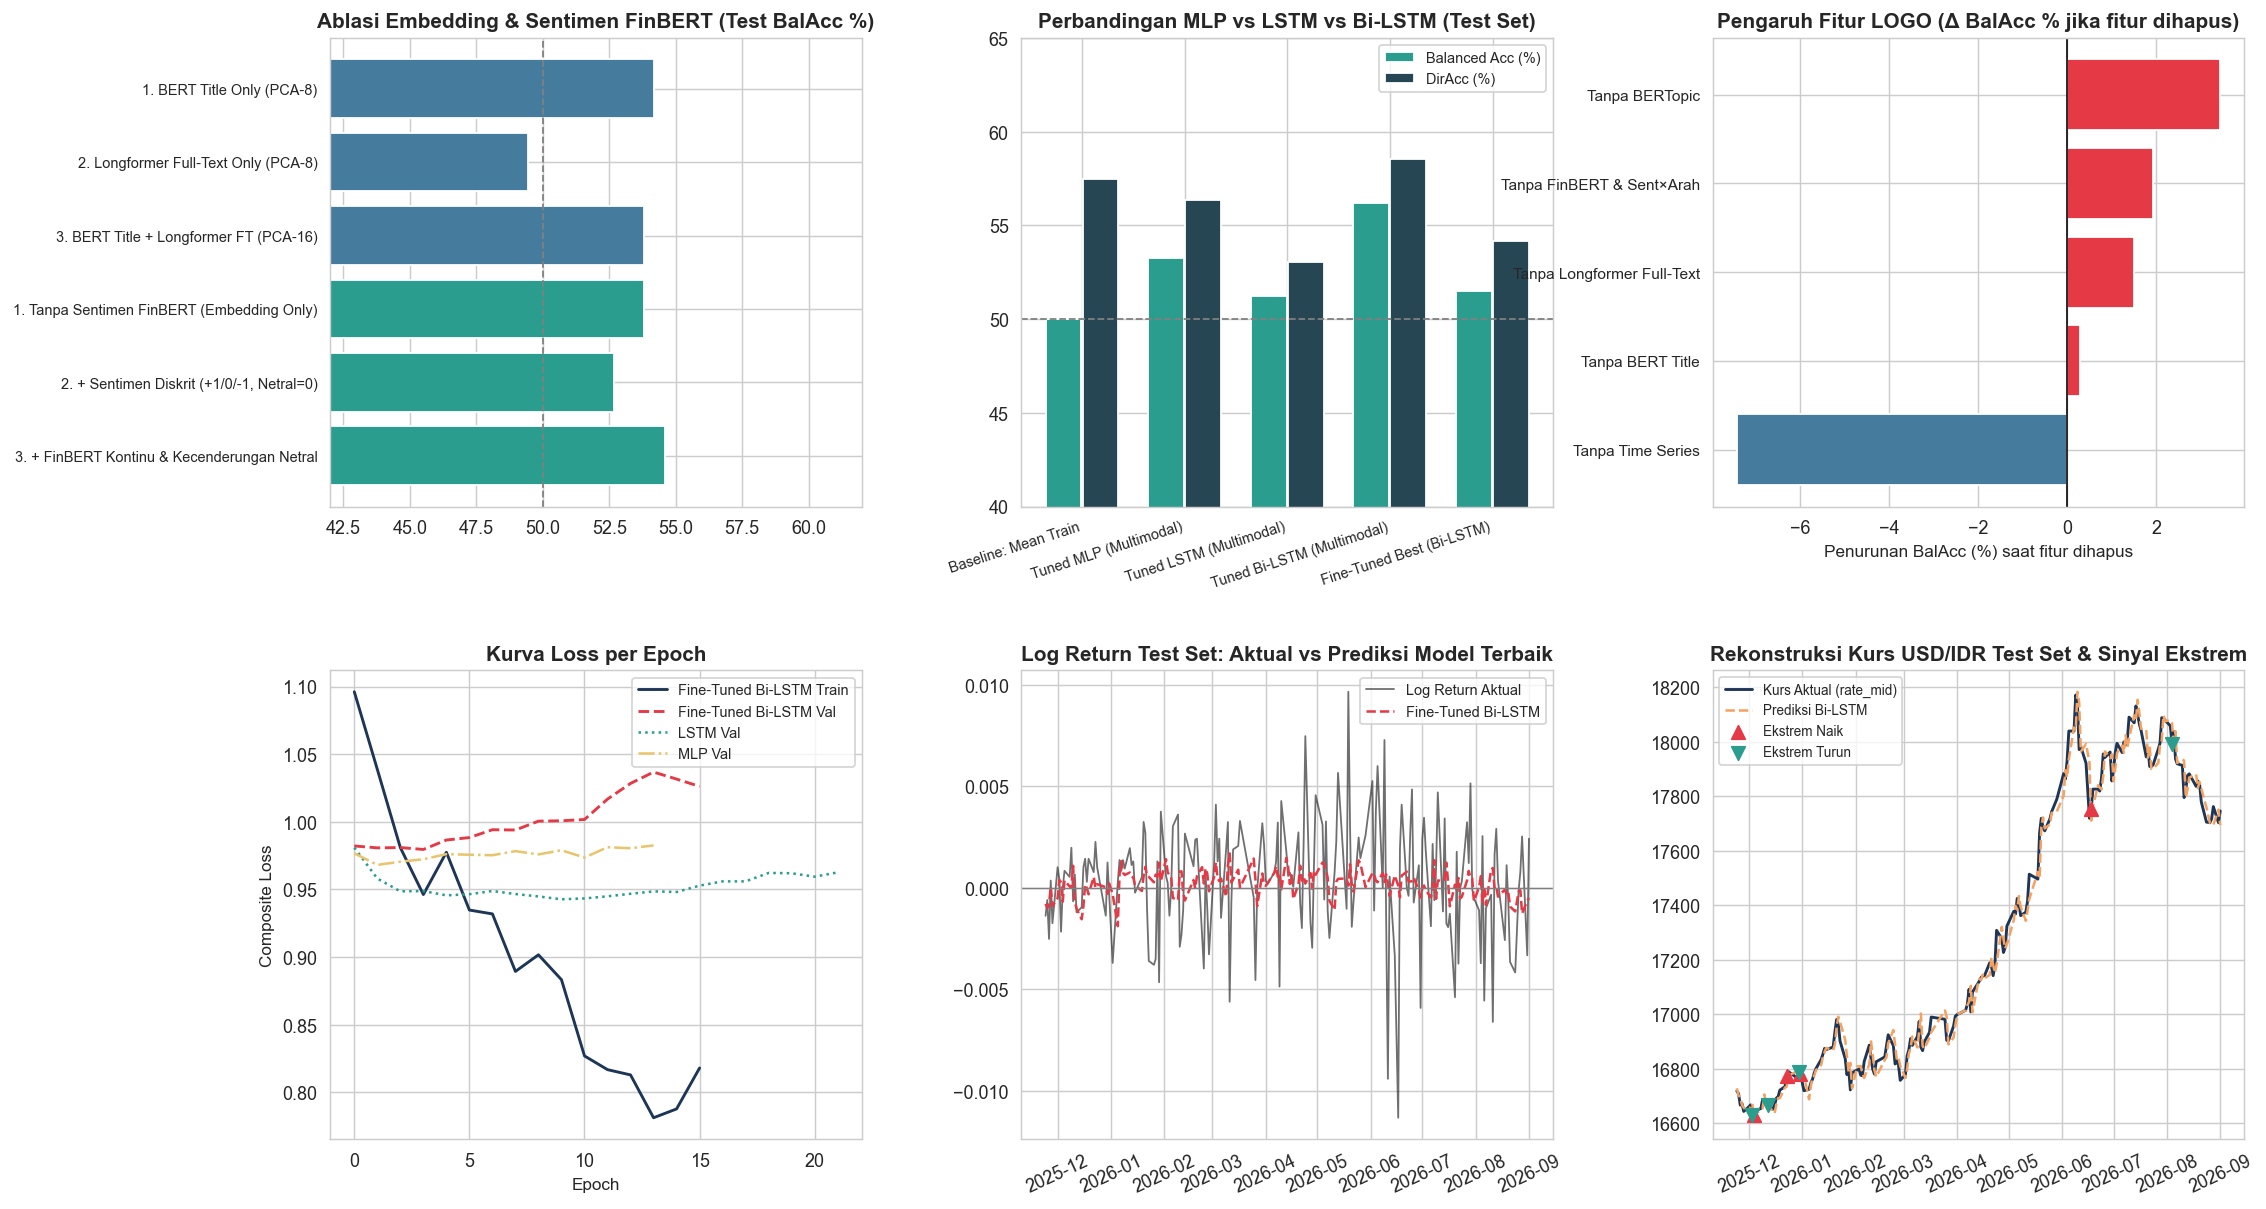

In [11]:
fig = plt.figure(figsize=(19, 11))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.30)

# 1. Studi Ablasi Embedding & Sentimen (Stage 1 BalAcc %)
ax1 = fig.add_subplot(gs[0, 0])
s1_ab_comb = pd.concat([
    emb_ablation_df[["Test BalAcc (%)"]].rename_axis("Skenario"),
    sent_ablation_df[["Test BalAcc (%)"]].rename_axis("Skenario"),
])
ax1.barh(s1_ab_comb.index, s1_ab_comb["Test BalAcc (%)"], color=["#457b9d"]*3 + ["#2a9d8f"]*3)
ax1.axvline(50.0, color="gray", linestyle="--", lw=1)
ax1.invert_yaxis()
ax1.set_xlim(42, max(62, s1_ab_comb["Test BalAcc (%)"].max() + 3))
ax1.set_title("Ablasi Embedding & Sentimen FinBERT (Test BalAcc %)")
ax1.tick_params(axis="y", labelsize=8)

# 2. Perbandingan MLP vs LSTM vs Bi-LSTM vs Fine-Tuned Best
ax2 = fig.add_subplot(gs[0, 1])
p_nn = neural_test_df.drop(["Baseline: Tebak Return 0"])
x_p = np.arange(len(p_nn))
ax2.bar(x_p - 0.18, p_nn["BalAcc (%)"], 0.35, label="Balanced Acc (%)", color="#2a9d8f")
ax2.bar(x_p + 0.18, p_nn["DirAcc (%)"], 0.35, label="DirAcc (%)", color="#264653")
ax2.axhline(50.0, color="gray", linestyle="--", lw=1)
ax2.set_xticks(x_p)
ax2.set_xticklabels(p_nn.index, rotation=18, ha="right", fontsize=8)
ax2.set_ylim(40, max(65, p_nn[["BalAcc (%)", "DirAcc (%)"]].max().max() + 3))
ax2.set_title("Perbandingan MLP vs LSTM vs Bi-LSTM (Test Set)")
ax2.legend(fontsize=8)

# 3. Pengaruh Fitur (Leave-One-Group-Out Delta BalAcc & Delta RMSE)
ax3 = fig.add_subplot(gs[0, 2])
cols_logo = ["#e63946" if v > 0 else "#457b9d" for v in logo_df["Delta BalAcc (full - tanpa)"]]
ax3.barh(logo_df.index, logo_df["Delta BalAcc (full - tanpa)"], color=cols_logo)
ax3.axvline(0, color="black", lw=0.9)
ax3.invert_yaxis()
ax3.set_title("Pengaruh Fitur LOGO (Δ BalAcc % jika fitur dihapus)")
ax3.set_xlabel("Penurunan BalAcc (%) saat fitur dihapus")
ax3.tick_params(axis="y", labelsize=8.5)

# 4. Kurva Loss Training/Val: MLP vs LSTM vs Bi-LSTM
ax4 = fig.add_subplot(gs[1, 0])
ax4.plot(res_best_tuned["tr_hist"], label=f"Fine-Tuned {best_arch_name} Train", color="#1d3557", lw=1.6)
ax4.plot(res_best_tuned["va_hist"], label=f"Fine-Tuned {best_arch_name} Val", color="#e63946", linestyle="--", lw=1.6)
ax4.plot(res_lstm_best["va_hist"], label="LSTM Val", color="#2a9d8f", linestyle=":", lw=1.4)
ax4.plot(res_mlp_best["va_hist"], label="MLP Val", color="#e9c46a", linestyle="-.", lw=1.4)
ax4.set_title("Kurva Loss per Epoch")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Composite Loss")
ax4.legend(fontsize=8)

# 5. Deret Waktu Log Return Aktual vs Prediksi Model Terbaik
te_seq_ref = seq_full_cache[best_fine_cfg.get("seq_len", 10)]
te_m_seq = te_seq_ref["split"] == "test"
te_dates = te_seq_ref["dates"][te_m_seq]
ax5 = fig.add_subplot(gs[1, 1])
ax5.plot(te_dates, y_te_true, label="Log Return Aktual", color="#222222", alpha=0.65, lw=1.0)
ax5.plot(te_dates, res_best_tuned["pred_te"], label=f"Fine-Tuned {best_arch_name}", color="#e63946", linestyle="--", lw=1.4)
ax5.axhline(0, color="gray", lw=0.8)
ax5.set_title("Log Return Test Set: Aktual vs Prediksi Model Terbaik")
ax5.tick_params(axis="x", rotation=25)
ax5.legend(fontsize=8)

# 6. Rekonstruksi Kurs USD/IDR + Penandaan Sentimen Ekstrem
ax6 = fig.add_subplot(gs[1, 2])
prev_r = te_seq_ref["prev_rate"][te_m_seq]
curr_r = te_seq_ref["curr_rate"][te_m_seq]
pred_r = prev_r * np.exp(res_best_tuned["pred_te"])
ax6.plot(te_dates, curr_r, label="Kurs Aktual (rate_mid)", color="#1d3557", lw=1.6)
ax6.plot(te_dates, pred_r, label=f"Prediksi {best_arch_name}", color="#f4a261", linestyle="--", lw=1.4)

te_align = df_model.loc[df_model[date_col].isin(te_dates)].copy()
ex_up = te_align[te_align["flag_naik_ekstrem"] == 1]
ex_dn = te_align[te_align["flag_turun_ekstrem"] == 1]
ax6.scatter(ex_up[date_col], ex_up["rate_mid"], marker="^", s=55, color="#e63946", zorder=5, label="Ekstrem Naik")
ax6.scatter(ex_dn[date_col], ex_dn["rate_mid"], marker="v", s=55, color="#2a9d8f", zorder=5, label="Ekstrem Turun")
ax6.set_title("Rekonstruksi Kurs USD/IDR Test Set & Sinyal Ekstrem")
ax6.tick_params(axis="x", rotation=25)
ax6.legend(fontsize=7.5)

plt.tight_layout()
plt.show()
